# 15-CNN与视觉特征学习


## 1. CNN 的整体结构

本篇依据课程资料《卷积神经网络CNN.pdf》的 **19 页内容**整理，原文标题为《01-CNN 入门》。按照资料顺序，介绍图像与特征、卷积、ReLU、池化、打平、批归一化、全连接层，以及反向传播、模型微调和迁移学习。

**CNN（Convolutional Neural Network，卷积神经网络）**通过卷积层等结构学习图像特征，再根据任务得到分类等输出。

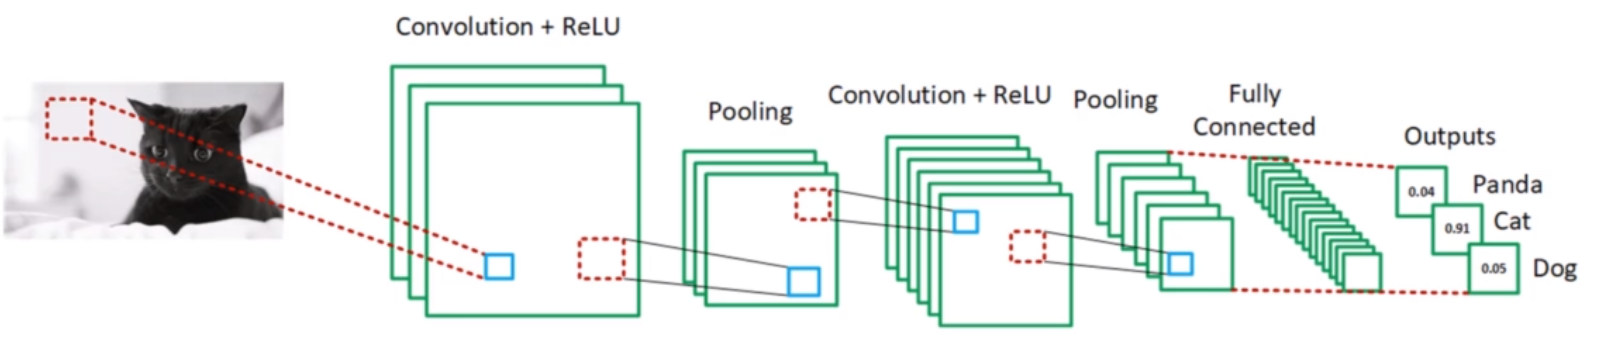

原图以图像分类为例：输入图片经过多次卷积与 ReLU、池化，再经过全连接部分，得到 Panda、Cat、Dog 等类别的输出。图中的 `0.04、0.91、0.05` 是示意数值，本篇没有运行这个分类模型。

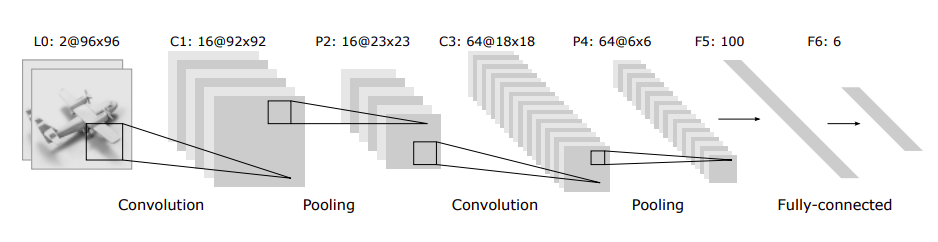

第二张图给出另一组结构示例：`2@96×96 → 16@92×92 → 16@23×23 → 64@18×18 → 64@6×6 → 100 → 6`。`16@92×92` 表示 16 张大小为 `92×92` 的特征图。这张图用于观察尺寸与通道变化，没有提供足以直接复现的完整层配置。


## 2. 图像为什么要提取特征

### 2.1 从视觉错觉理解特征

资料先用两张人脸错觉图说明：我们关注不同的局部特征时，对同一幅图像可能产生不同感受。

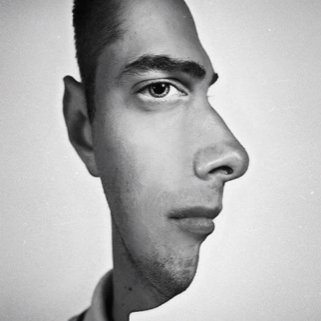

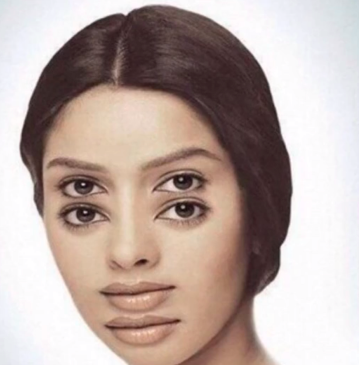

这里的 **feature（特征）**可以理解为帮助区分图像内容的模式，例如边缘、纹理、眼睛和轮廓。课件把 CNN 的处理过程类比为人依靠特征识别对象，这是教学类比，并不表示 CNN 与人脑的工作机制相同。

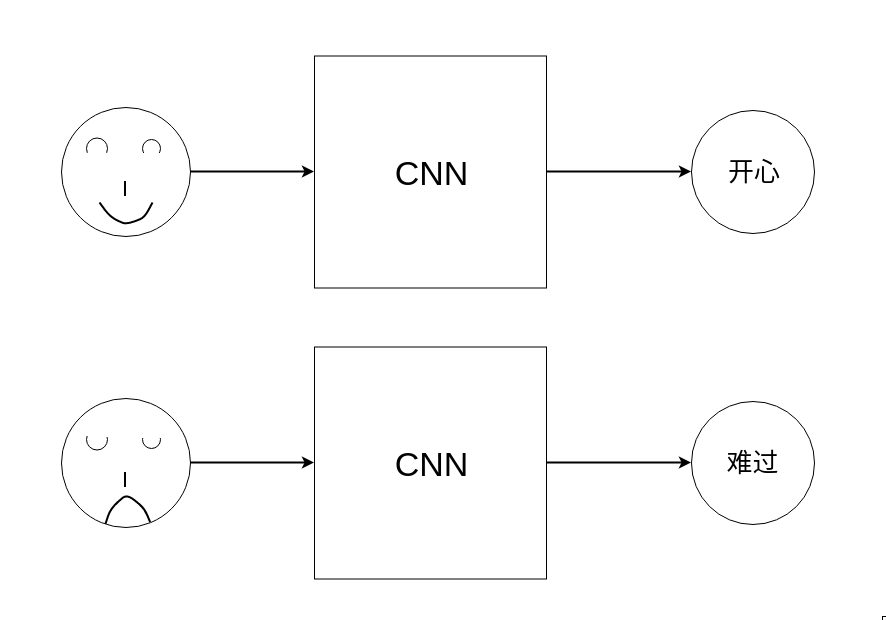

图中用笑脸和哭脸对应“开心”“难过”，说明模型需要从输入图像计算类别。实际模型输出的是任务定义的标签，不能仅凭表情图片确定一个人的真实内心感受。

### 2.2 图像在计算机中的表示

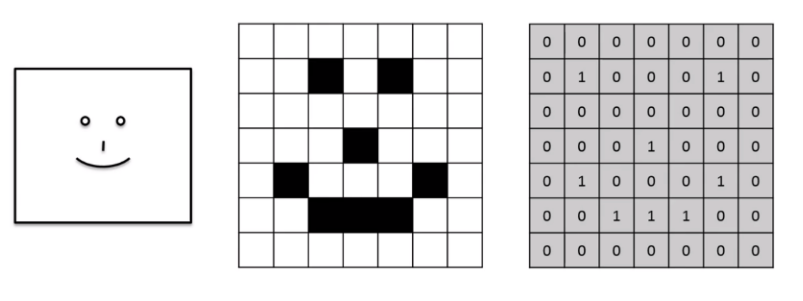

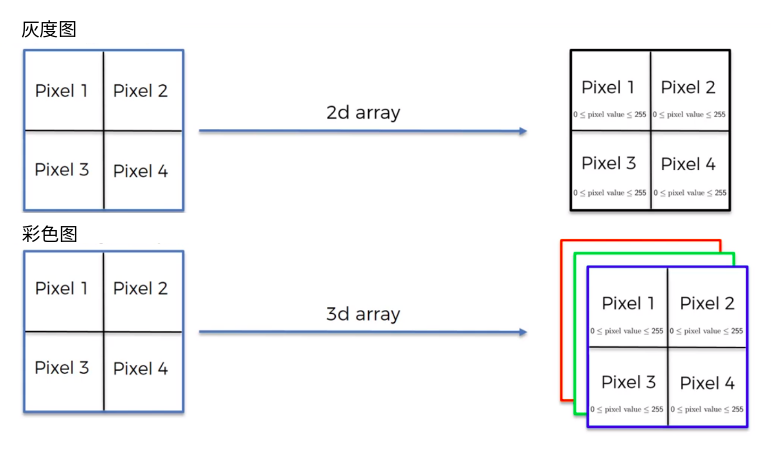

| 图像形式 | 课件中的表示 |
|---|---|
| 二值示意图 | 用 `0`、`1` 构成矩阵，表示图案 |
| 灰度图 | 二维数组，每个位置对应一个像素值 |
| RGB 彩色图 | 三个颜色通道，常表示为 `H×W×3` 的数组 |

原图标出的 `0～255` 对应常见 8 位图像。**补充：**网络输入也可以经过缩放、标准化等处理，此时数值范围不必仍然是 `0～255`。


## 3. 卷积核与 OpenCV 滤波示例

资料从 OpenCV 的卷积核讲起，把它称为“特征提取器”：一个小矩阵在图像上滑动，对局部像素加权求和，得到不同位置的响应。

### 3.1 不同卷积核产生不同效果

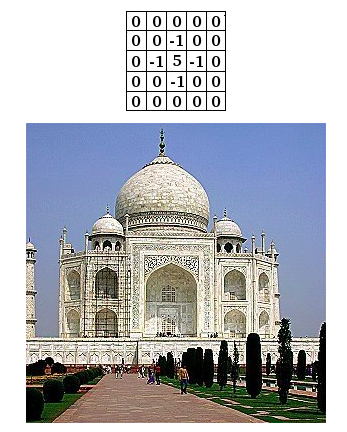

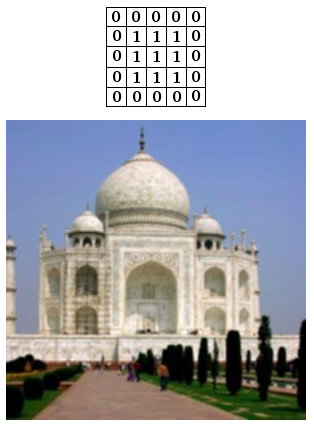

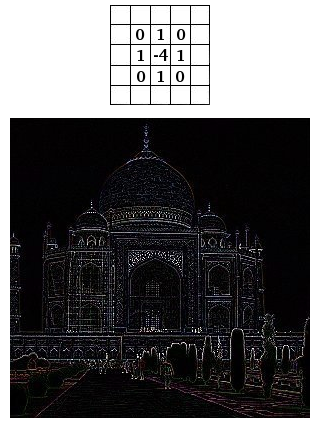

三张图分别展示锐化、模糊和边缘响应。原图中的模糊核在中心 `3×3` 区域写了 9 个 `1`，没有标出归一化系数。若希望计算局部均值，需要让权重之和为 `1`。

### 3.2 原课代码

下面保留第 5 页的代码逻辑、变量和注释，仅整理空格。代码以当前工作目录中的 `a.jpg` 为输入，实际阅读或运行时需要自行准备这张图片。

```python
import matplotlib.pyplot as plt
import pylab
import cv2
import numpy as np

img = plt.imread("a.jpg")
plt.imshow(img)                         # 显示原图
pylab.show()

fil = np.array([[1, 1, 1],               # 卷积核
                [1, 1, 1],
                [1, 1, 1]])

res = cv2.filter2D(img, -1, fil)         # 使用 opencv 的卷积函数
plt.imshow(res)                         # 显示卷积后的图片
pylab.show()
```

`cv2.filter2D` 的第二个参数 `-1` 表示输出沿用输入的数据深度，也就是像素数值类型。它与后面所说的特征图通道数是不同概念。

> **原代码辨析：**这个 `fil` 的权重之和是 `9`，执行的是局部求和。它没有除以 `9`，因此不能把结果直接理解为均值模糊。若输入是 `uint8`，较大的结果可能饱和到 `255`。本篇保留原代码，不把示意图当作它的已验证输出。

**补充：**若目的是均值滤波，可使用 `fil = np.ones((3, 3), dtype=np.float32) / 9.0`。另外，`filter2D` 实际采用不翻转核的互相关计算，CNN 中通常也沿用这种计算，并习惯称为卷积。


## 4. 卷积怎样得到特征图

### 4.1 滑动窗口与逐元素乘加

第 6 页使用一个 `7×7` 输入和一个 `3×3` 卷积核，步长为 `1`，不填充，得到 `5×5` 的特征图。

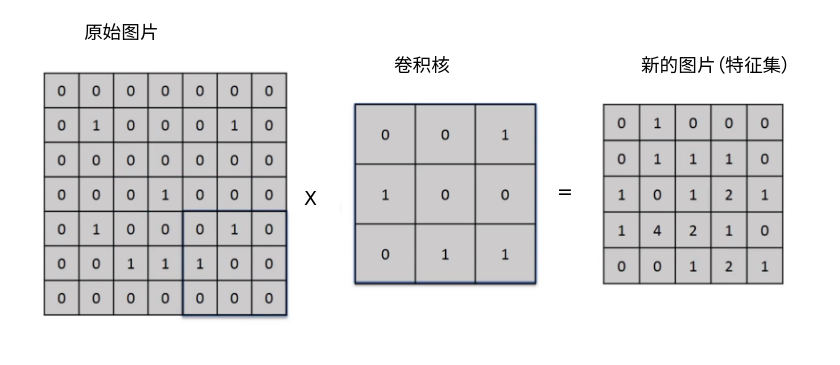

图中的卷积核为：

```text
0 0 1
1 0 0
0 1 1
```

每次取输入中对应的 `3×3` 区域，与核逐元素相乘，再把乘积相加，得到一个输出。随后将窗口移动一个位置，重复计算。较大的响应表示该位置与这个核所强调的模式更吻合。

**原图数值校正：**按图中输入和卷积核逐项计算，输出第 3 行第 3 列应为 `0`，原图写成了 `1`。该窗口与核的非零位置没有重合，乘积之和为 `0`。校正后的完整结果是：

```text
0 1 0 0 0
0 1 1 1 0
1 0 0 2 1
1 4 2 1 0
0 0 1 2 1
```

### 4.2 从人工设计核到学习卷积核

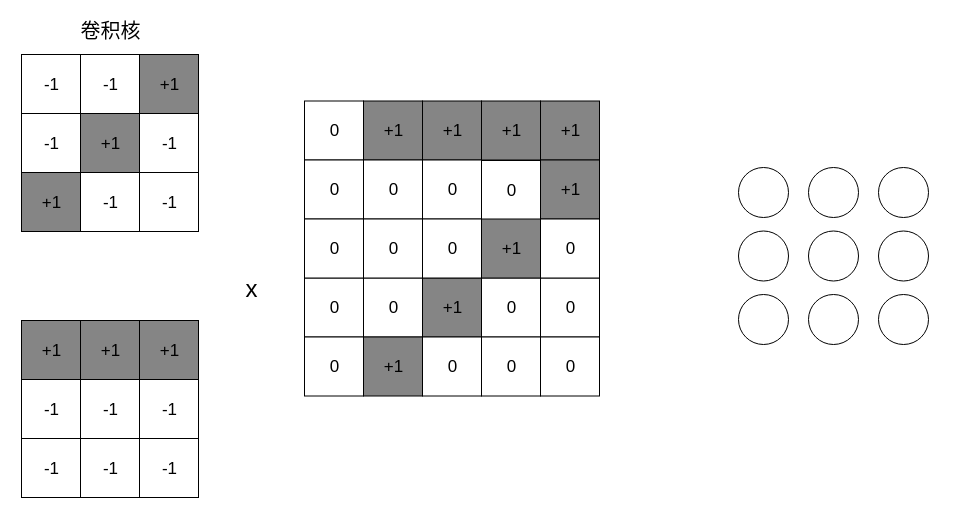

课件用不同的 `+1`、`-1` 排列强调不同方向的图案。传统图像处理常根据经验设计滤波器，CNN 则通过训练学习适合任务的核权重。

资料列出四个目的：减少需要处理的数据、突出鼻子和眼睛等特征、通过训练寻找合适的核，以及强化关键信息并弱化无关信息。它用 `64×64×3 = 12288` 个数值，与 `1920×1080` 的大图作比较。

**补充辨析：**卷积是否减少数据量取决于步长、填充和输出通道数。空间尺寸不变或通道数增多时，总元素数可能不降反升。资料提到的“中值卷积核”也应理解为中值滤波，取中值是非线性操作，不能由一个固定线性卷积核实现。


## 5. 卷积核大小、通道数、步长与填充

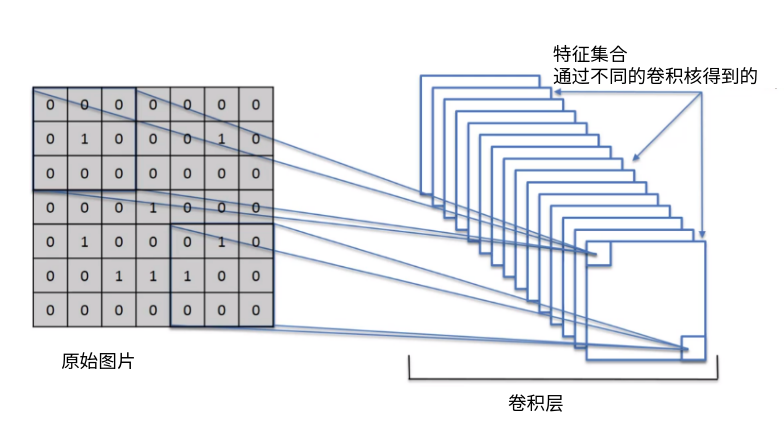

| 参数 | 作用 | 课件中的说明 |
|---|---|---|
| `kernel size` | 决定每次处理的局部范围 | 例如 `3×3`、`5×5` |
| `depth` | 此处指卷积输出的通道数 | 用多少个特征提取器，得到多少张特征图 |
| `stride`，记为 `S` | 决定窗口每次移动的距离 | 常用 `1`，大图可考虑 `2` |
| `padding`，记为 `P` | 在边界补充数值 | 常用零填充，配合其他参数保持空间大小 |

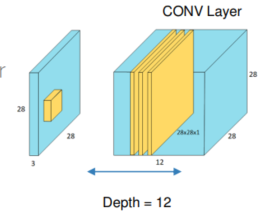

图中的 `Depth = 12` 表示输出有 12 个通道，输入 RGB 的通道数是 `3`。**补充：**普通稠密卷积的一个滤波器会覆盖全部输入通道，其权重可理解为 `K×K×C_in`。多个滤波器生成多个输出通道，这与网络一共堆叠了多少层也要区分。

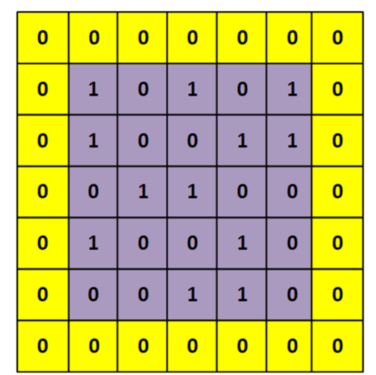

### 5.1 输出空间尺寸

第 8 页给出尺寸公式。把“除不尽只保留整数位”写成向下取整，可表示为：

$$
O = \left\lfloor\frac{I+2P-K}{S}\right\rfloor+1
$$

`I` 为输入在某一方向上的长度，`K` 为核在该方向上的大小，`P` 为两端各自的填充量，`S` 为步长，`O` 为输出长度。宽、高分别计算。这里假设普通卷积、无空洞扩张，且窗口尺寸有效。

课件例子：`I=5，K=3，P=1，S=1`，因此：

$$
O = \frac{5+2\times1-3}{1}+1=5
$$

所以 `5×5` 输入经过这一配置后仍为 `5×5`。若同样的输入不填充，则变成 `3×3`。零填充能否保持大小，需要与核大小、步长一起判断。


## 6. ReLU：引入非线性

第 8～9 页介绍 **ReLU（Rectified Linear Unit）**。它逐元素计算：

$$
\operatorname{ReLU}(x)=\max(0,x)
$$

正数保持不变，负数变成 `0`，`0` 仍然是 `0`。

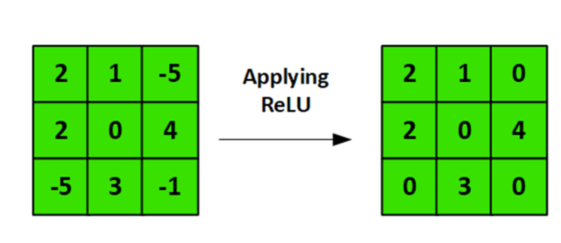

图中的 `-5`、`-1` 被置为 `0`，其他值不变，输入和输出的形状相同。

> **原文辨析：**资料用“负像素没有意义”“过滤非法数值”解释 ReLU。卷积结果已经是特征响应，负数完全可以有意义。ReLU 是一种非线性激活选择，不能把所有负响应都视为非法数据。


## 7. 池化：保留局部响应并缩小空间尺寸

第 9～12 页介绍 **pooling（池化）**，重点是 **max pooling（最大池化）**：在每个局部窗口中取最大值。

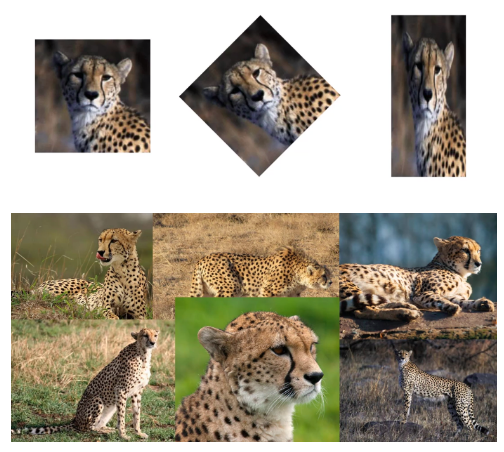

课件用动物的纹理、鼻子与脸部轮廓说明特征识别，希望模型在外观变化后仍能识别对象。池化可以降低对某些小范围位置变化的敏感性，但它本身并不求解物体的位置或旋转角度。

### 7.1 步长为 2 的最大池化

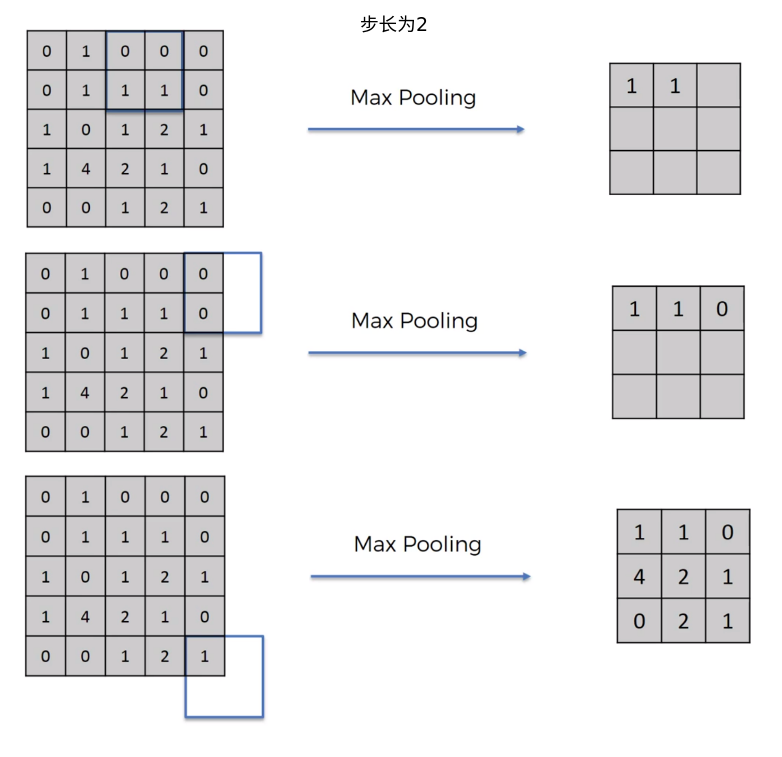

图中使用 `2×2` 窗口、步长 `2`，每个窗口只保留最大值。右侧和下侧还保留了不足 `2×2` 的边界窗口，最终给出：

```text
1 1 0
4 2 1
0 2 1
```

**边界说明：**原图得到 `3×3` 输出，包含了边界窗口。若采用不填充、只处理完整窗口的规则，`5×5` 输入会输出 `2×2`，结果为 `[[1, 1], [4, 2]]`。复现时必须明确填充或向上取整等边界设置，不能只写“步长为 2”。前面卷积图中那一处数值笔误，不影响这些池化窗口的最大值。

### 7.2 4×4 缩小为 2×2 的例子

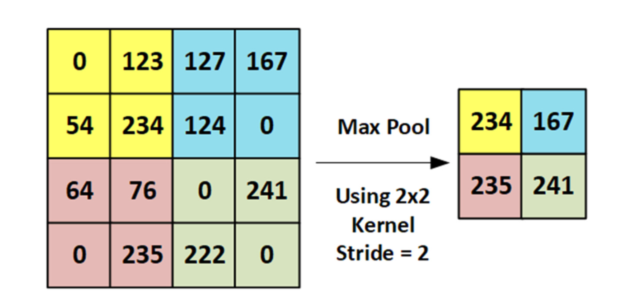

这一例子使用 `2×2` 窗口、步长 `2`，输入大小刚好可以整除。输出为 `[[234, 167], [235, 241]]`，从 16 个值降到 4 个值，减少 `75%`。

课件还把减少过拟合风险作为池化的可能好处。**补充辨析：**“减少 75%”适用于宽、高各减半且通道数不变的情况，并非所有池化配置都如此。最大池化通常没有可训练参数，主要减少的是激活数据和后续计算，也可能减少后续全连接层的参数。它不保证消除过拟合，也不保证任意旋转后特征完全不变。

资料给出的论文入口为 [Max-pooling 相关论文](http://ais.uni-bonn.de/papers/icann2010_maxpool.pdf)，本篇按课程图示整理，没有重新复现论文实验。


## 8. Flatten：将特征图打平

第 12～13 页介绍 **flattening（打平）**，把空间特征图重新排列成一维向量，便于连接后面的全连接层。

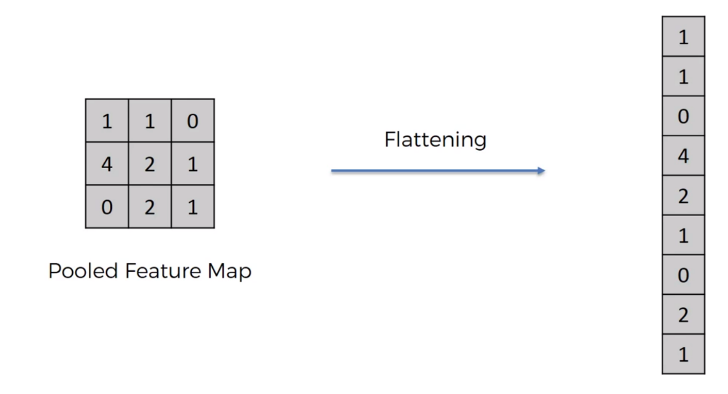

图中矩阵按行展开为：

```text
[1, 1, 0, 4, 2, 1, 0, 2, 1]
```

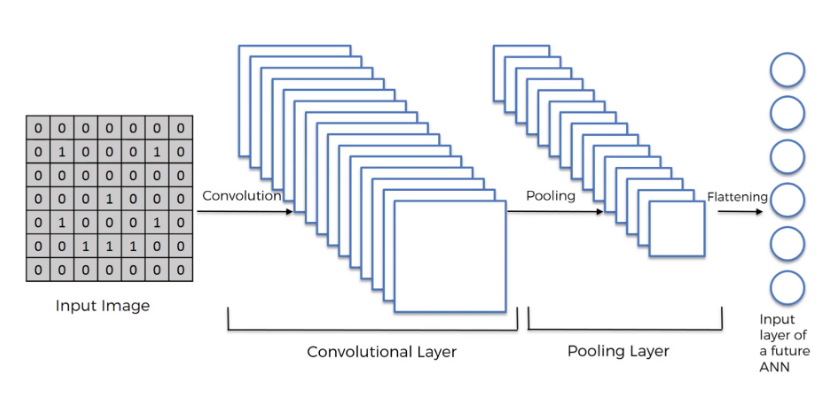

**概念辨析：**课件把这一步称为“降维”。这里降低的是数组的轴数，元素数量并没有减少。`H×W×C` 的特征张量打平后有 `HWC` 个元素，展开顺序由具体实现约定。


## 9. Batch Normalization：批归一化

第 13～14 页介绍 **Batch Normalization（BN）**，对网络中间的数值进行归一化处理，再传给后续层。

**简要补充：**训练时，BN 使用当前批次的统计量进行标准化，再通过可学习的缩放和平移调整结果。普通推理阶段通常使用训练中维护的统计量。它与把图片统一除以 `255` 的输入预处理不同。

课件给出的调用片段是：

```python
model.add(BatchNormalization())
```

这是向已有模型添加一层的片段，原资料未给出导入语句、模型定义和该层的具体放置位置。

| 课件列出的影响 | 理解方式 |
|---|---|
| 帮助收敛，减少 `epochs` | 可能减少完成训练所需的轮数，`epoch` 指遍历训练数据一轮 |
| 帮助缓解 `overfitting` | 可能有一定正则化作用，效果依赖任务和设置 |
| 提高稳定性，允许较大的学习率 | 可以改善优化过程，但学习率仍然需要选择 |
| 缺点：降低训练速度 | 增加每一步的统计与计算开销 |

“训练步耗时增加”和“达到目标所需轮数减少”可以同时发生，总训练时间要看实际情况。BN 不是解决过拟合或保证收敛的通用开关。


## 10. 全连接层与完整 CNN 流程

第 14 页介绍 **FC（Fully Connected，全连接）层**。前面的部分提取特征，打平后，全连接层综合这些特征，得到分类等任务需要的输出。

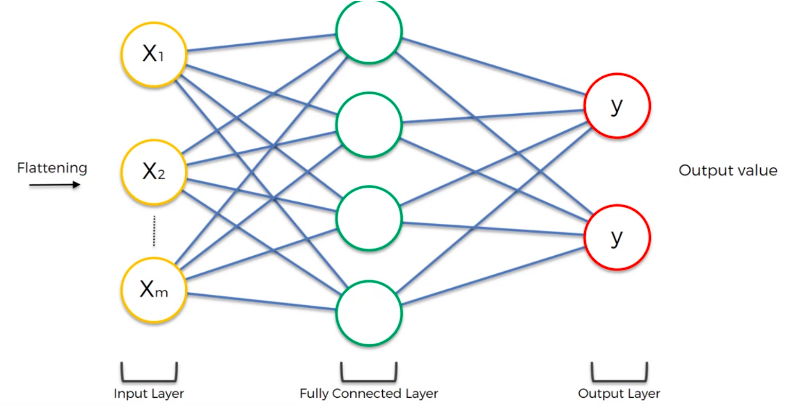

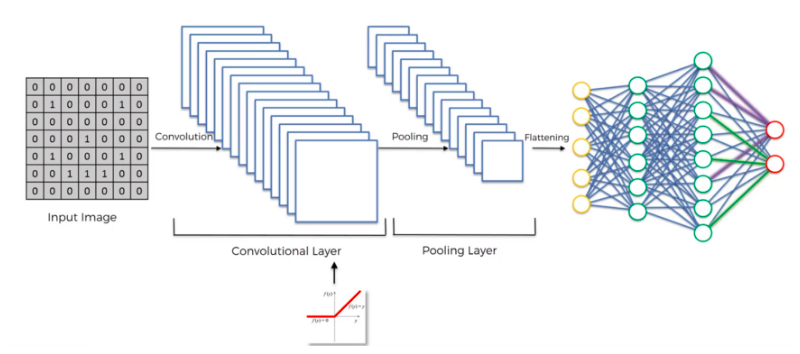

沿着图中的流程，输入先经过卷积与激活，再经过池化，随后打平，最后由全连接部分计算输出。

**表述补充：**原文说“卷积提取特征，再交给神经网络”。卷积层本身就是神经网络的一部分，常规 CNN 训练时，卷积核与分类部分的参数可以一起通过反向传播学习，并非先固定地处理图片，再训练一个完全独立的网络。


## 11. 课件中的 CNN 设计建议

第 15 页给出一组入门配置建议。这些是设计起点，需要结合具体任务与张量尺寸使用。

| 项目 | 课件建议 | 适用条件或补充说明 |
|---|---|---|
| 输入形状 | `28×28×3`、`64×64×3`、`128×128×3`，宽高尽量相同 | 这是 RGB 示例，CNN 也可以处理非正方形或单通道输入 |
| 输入大小 | 能被 `4` 整除，方便下采样 | 对两次各缩小一半的配置较方便，不是 CNN 的硬性要求 |
| 卷积核 | 常用 `3×3` 或 `5×5` | 影响局部感受范围与计算量 |
| 步长 | 常用 `1`，大图可考虑 `2` | 步长增大通常会降低输出空间分辨率 |
| 零填充 | 需要保持图像大小时考虑使用 | 仍要按尺寸公式核对核大小与步长 |
| 池化窗口 | 常用 `2×2` | 配合步长 `2` 且边界匹配时，空间元素数降为约四分之一 |
| Dropout | 用于缓解过拟合 | 训练时随机丢弃部分单元的输出，效果依赖丢弃比例和模型 |
| 层级数量 | 更多层可以学习更丰富的特征 | 层数增加也影响计算和优化难度，性能不会必然提升 |

课件给出的典型顺序为：

```text
Input → Conv → ReLU → Pool → Conv → ReLU → Pool → FC → Output
```

这是一种常见的入门结构，不能理解为所有 CNN 都必须逐项采用这一组合。


## 12. 反向传播怎样学习参数

第 15～16 页通过决策边界和网络连线，回顾 **backpropagation（反向传播）**。

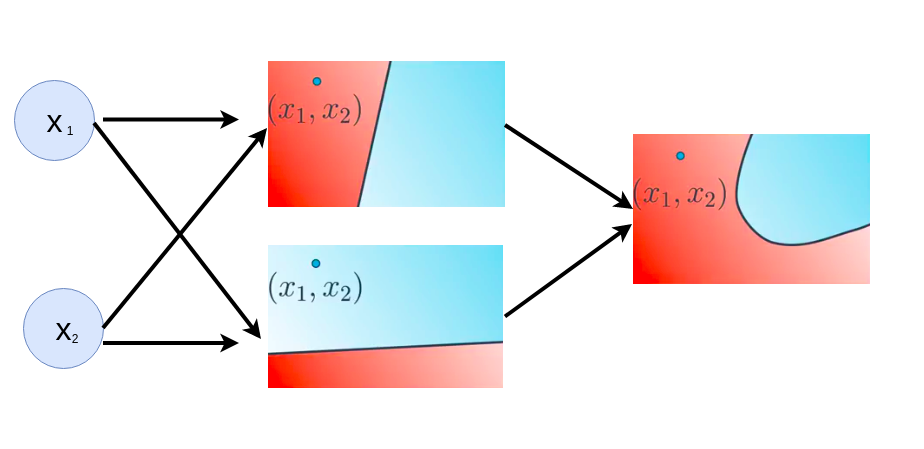

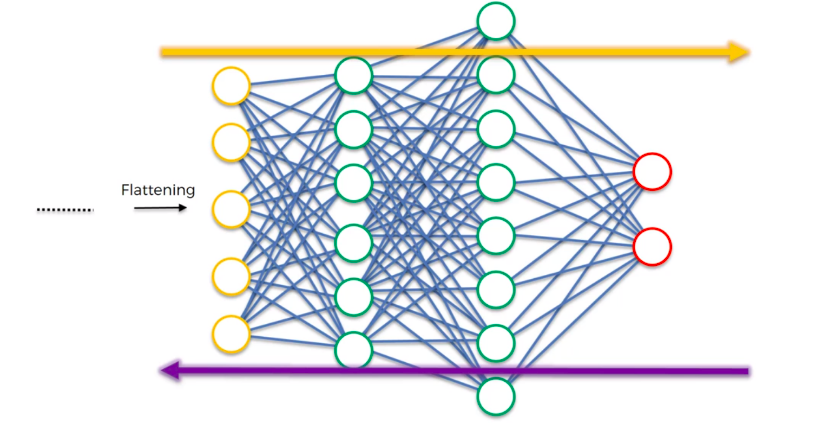

黄色箭头表示从输入到输出的计算方向，紫色箭头表示从输出端向前面各层传播梯度的方向。

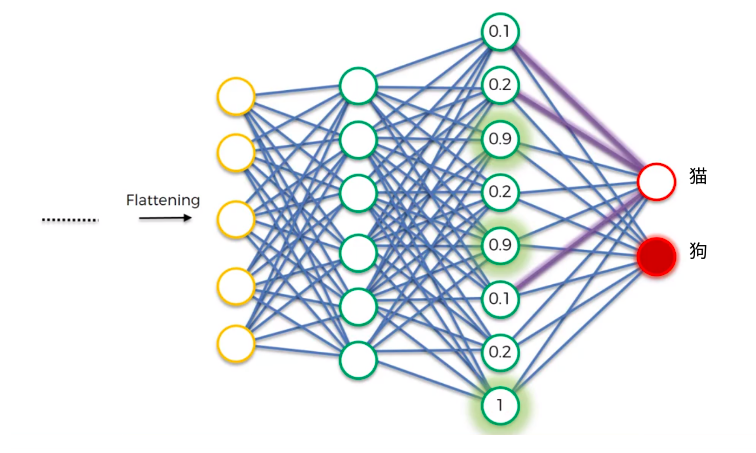

原文用“强者更强、弱者更弱”和“正确的点离我远点、错误的点离我近点”作直观类比。**补充说明：**实际训练是先计算预测与目标之间的损失，再用链式法则求出各参数对损失的梯度，由优化器更新参数。不能根据某个节点数值大，就断言所有相连权重都应增大。

为了说明更新方向，可以用普通梯度下降表示为：

$$
\theta \leftarrow \theta-\eta\nabla_{\theta}L
$$

这是解释用的补充公式：`θ` 是待学习参数，`η` 是学习率，`L` 是损失。反向传播负责计算梯度，优化器利用梯度更新参数。课件没有给出具体损失函数或完整训练代码。


## 13. 常见 CNN 模型

第 16～17 页列出 LeNet、AlexNet、Inception、VGGNet、ResNet，并给出下列历史比较表。

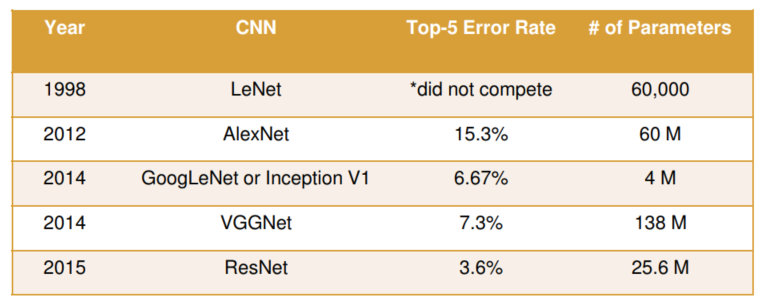

| 年份 | 模型 | 原表 Top-5 Error Rate | 原表参数数量 |
|---|---|---|---|
| 1998 | LeNet | 未参赛（`did not compete`） | 60,000 |
| 2012 | AlexNet | 15.3% | 60 M |
| 2014 | GoogLeNet / Inception V1 | 6.67% | 4 M |
| 2014 | VGGNet | 7.3% | 138 M |
| 2015 | ResNet | 3.6% | 25.6 M |

`M` 表示百万参数。**Top-5 错误率**指真实类别未出现在模型得分最高的 5 个类别中的比例，在相同评测条件下越低越好。

**读表边界：**这是课件历史对比，原表没有完整注明模型深度、单模型或集成设置及评测条件。特别是 ResNet 一行，不能仅据表格把 `3.6%` 与 `25.6 M` 当作同一个明确版本的可复现实验结果。模型家族名称也不代表唯一参数规模。


## 14. 模型微调与迁移学习

第 17 页以已有的图像分类网络为例，说明怎样复用训练得到的特征。

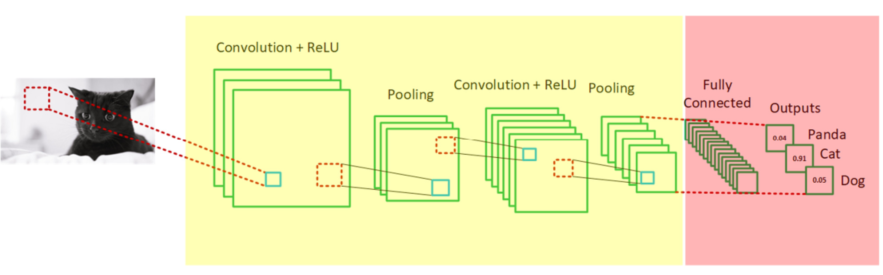

课件流程分为两步：

1. 冻结前面的卷积层，保留已经学到的特征提取能力。
2. 重新训练红色区域，即后面的全连接与输出部分，使其适配目标任务。

“冻结”指训练时不更新选定层的参数，这些层仍然参与前向计算。**补充：**目标类别变化时，通常也需要调整分类输出层。课件没有给出冻结代码或具体输出层定义。

**迁移学习（Transfer Learning）**是把已有任务中学到的知识用于新任务，资料举例用 VGG16 识别猴子和大猩猩。

**术语辨析：**课件把“冻结卷积层，只训练分类部分”放在 `fine-tuning` 标题下。更细分时，这一步常称为使用固定的预训练特征提取器；微调通常还包括解冻部分预训练层、在新任务上继续更新它们。两者都是复用预训练模型的做法，课件这里只展开前一种。


## 15. 死亡 ReLU 与其他激活函数

第 18 页回到 ReLU 的局限。若某个单元对训练数据长期得到负的激活前输入，经过 ReLU 后持续输出 `0`，负半轴的局部梯度也为 `0`，这个单元就可能难以继续学习，这通常称为 **dying ReLU（死亡 ReLU）**。

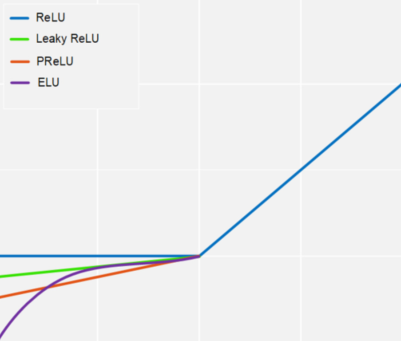

图中列出几种处理负半轴的方式。下面是帮助读图的简要说明：

| 激活函数 | 负半轴的处理方式 |
|---|---|
| ReLU | 输出 `0` |
| Leaky ReLU | 保留一条斜率较小的直线 |
| PReLU | 使用可学习的负半轴斜率 |
| ELU | 使用向负值饱和的指数分支 |

**原文辨析：**死亡 ReLU 并不限于输出层，一次输出 `0` 也不等于单元死亡。课件说“负反馈需要传递”，这里应理解为激活函数负半轴的梯度传播问题，与前面机械臂控制中的负反馈概念不同。

课件建议一般先使用 ReLU，再尝试其他激活函数。原文称 ELU 为“最近新研发”，属于资料当时的表述。比较激活函数和其他超参数应使用验证集，不能反复依据测试集成绩调参后仍把它当作独立测试结果。


## 16. Fashion-MNIST、表情分类与实验入口

### 16.1 Fashion-MNIST 的十个类别

第 18 页列出以下服饰类别。表格按课件顺序整理，用于认识任务标签。

| 英文 | 中文 | 英文 | 中文 |
|---|---|---|---|
| `t-shirt` | T 恤 | `sandal` | 凉鞋 |
| `trousers` | 裤子 | `shirt` | 衬衫 |
| `pullover` | 套衫、毛衫 | `sneaker` | 运动鞋 |
| `dress` | 裙子 | `bag` | 包包 |
| `coat` | 外套 | `ankle boot` | 短靴 |

**补充：**Fashion-MNIST 的图像是 `28×28` 灰度图，通常按一个通道处理，不能直接把前面 `28×28×3` 的 RGB 示例当作其原始形状。上表是类别对照，未定义数据集的数字标签顺序。

### 16.2 little-VGG 表情分类

第 18～19 页以“感情识别 little-VGG”为标题，列出七个类别：

| 标签 | 含义 |
|---|---|
| `angry` | 愤怒 |
| `happy` | 开心 |
| `neutral` | 中性表情 |
| `disgust` | 厌恶 |
| `sad` | 悲伤 |
| `fear` | 恐惧 |
| `surprise` | 惊讶 |

这部分给出了任务名称和类别，没有提供 little-VGG 的具体层结构、数据划分、训练脚本或准确率。应把它理解为表情标签分类示例。

资料最后提供 [Google Colab](https://colab.research.google.com/) 作为实验入口，没有给出具体 Notebook 链接。本篇保留源代码片段、图示与公式说明，没有补造训练结果或机械臂视觉模型部署流程。
